In [1]:
# ═══════════════════════════════════════════════════════════════════
# CELL 1: Install dependencies and imports
# ═══════════════════════════════════════════════════════════════════

!pip install pennylane torch torchvision scikit-learn seaborn pydicom --quiet

import os, numpy as np, torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import DataLoader, Dataset, ConcatDataset
from torchvision import datasets, transforms
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
import pydicom
from PIL import Image
from collections import Counter
import pennylane as qml

# Device & Config
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_QUBITS, BATCH, SEED = 4, 16, 42

# Paths - UPDATE THESE FOR YOUR SYSTEM
PRETRAINED_PATH = r"C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\qcnn_phase3_best.pth"
ICMR_ROOT = r"C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\intbtr254"
SAVE_DIR = r"C:\Users\rames\OneDrive\Documents\All coding projects\QML Tuberclosis project\icmr_finetuned"

os.makedirs(SAVE_DIR, exist_ok=True)
torch.manual_seed(SEED); np.random.seed(SEED)

print(f"✅ Setup complete | Device: {DEVICE}")
print(f"Pretrained: {os.path.exists(PRETRAINED_PATH)} | ICMR: {os.path.exists(ICMR_ROOT)}")

✅ Setup complete | Device: cpu
Pretrained: True | ICMR: True


In [2]:
# ═══════════════════════════════════════════════════════════════════
# CELL 2: PennyLane quantum device and circuit
# ═══════════════════════════════════════════════════════════════════

dev = qml.device("lightning.qubit", wires=N_QUBITS, shots=None)

@qml.qnode(dev, interface="torch", diff_method="adjoint")
def quantum_circuit(inputs, weights_layer1, weights_layer2, weights_entangle):
    """Optimized 2-layer circuit with data re-uploading"""
    # Layer 1
    for i in range(N_QUBITS):
        qml.RY(inputs[i] * np.pi, wires=i)
        qml.RX(weights_layer1[i, 0], wires=i)
        qml.RY(weights_layer1[i, 1], wires=i)
    for i in range(N_QUBITS): qml.CNOT(wires=[i, (i+1) % N_QUBITS])
    
    # Layer 2: Re-upload
    for i in range(N_QUBITS):
        qml.RY(inputs[i] * np.pi * 0.5, wires=i)
        qml.RX(weights_layer2[i, 0], wires=i)
        qml.RY(weights_layer2[i, 1], wires=i)
        qml.CRZ(weights_entangle[i], wires=[i, (i+2) % N_QUBITS])
    
    return qml.expval(qml.PauliZ(N_QUBITS-1))

print("✅ Quantum circuit ready")

✅ Quantum circuit ready


In [3]:
# ═══════════════════════════════════════════════════════════════════
# CELL 3: Hybrid QCNN model (same architecture as your 93% model)
# ═══════════════════════════════════════════════════════════════════

class HybridQCNN(nn.Module):
    def __init__(self, n_qubits=N_QUBITS):
        super().__init__()
        # ResNet18 backbone (frozen)
        from torchvision import models
        res = models.resnet18(weights=None)  # Load architecture only
        for p in res.parameters(): p.requires_grad = False
        self.backbone = nn.Sequential(*list(res.children())[:-1])
        
        # Projector
        self.projector = nn.Sequential(
            nn.Flatten(), nn.Linear(512, n_qubits), nn.Tanh()
        )
        
        # Quantum parameters
        self.q_weights_l1 = nn.Parameter(torch.randn(n_qubits, 2) * 0.1)
        self.q_weights_l2 = nn.Parameter(torch.randn(n_qubits, 2) * 0.1)
        self.q_weights_ent = nn.Parameter(torch.randn(n_qubits) * 0.1)
        
        # Classification head
        self.classifier = nn.Sequential(
            nn.Linear(1, 32), nn.ReLU(), nn.Dropout(0.5), nn.Linear(32, 2)
        )
        
    def forward(self, x):
        x = self.backbone(x)
        x = self.projector(x) * np.pi
        
        # Batch quantum processing
        q_out = []
        for i in range(x.size(0)):
            q_val = quantum_circuit(x[i], self.q_weights_l1, self.q_weights_l2, self.q_weights_ent)
            q_out.append(q_val)
        q_out = torch.stack(q_out).unsqueeze(1)
        
        return self.classifier(q_out)

# Initialize model
model = HybridQCNN().to(DEVICE)
print(f"✅ Model initialized | Total params: {sum(p.numel() for p in model.parameters()):,}")

✅ Model initialized | Total params: 11,178,714


In [6]:
# ═══════════════════════════════════════════════════════════════════
# DIAGNOSTIC: Inspect checkpoint keys & shapes
# ═══════════════════════════════════════════════════════════════════
checkpoint = torch.load(PRETRAINED_PATH, map_location=DEVICE)
state_dict = checkpoint.get('model_state_dict', checkpoint)

print("── Checkpoint keys & shapes ──")
for k, v in state_dict.items():
    print(f"  {k:45s} {tuple(v.shape)}")

print("\n── Current model keys & shapes ──")
for k, v in model.state_dict().items():
    print(f"  {k:45s} {tuple(v.shape)}")

── Checkpoint keys & shapes ──
  backbone.0.weight                             (64, 3, 7, 7)
  backbone.1.weight                             (64,)
  backbone.1.bias                               (64,)
  backbone.1.running_mean                       (64,)
  backbone.1.running_var                        (64,)
  backbone.1.num_batches_tracked                ()
  backbone.4.0.conv1.weight                     (64, 64, 3, 3)
  backbone.4.0.bn1.weight                       (64,)
  backbone.4.0.bn1.bias                         (64,)
  backbone.4.0.bn1.running_mean                 (64,)
  backbone.4.0.bn1.running_var                  (64,)
  backbone.4.0.bn1.num_batches_tracked          ()
  backbone.4.0.conv2.weight                     (64, 64, 3, 3)
  backbone.4.0.bn2.weight                       (64,)
  backbone.4.0.bn2.bias                         (64,)
  backbone.4.0.bn2.running_mean                 (64,)
  backbone.4.0.bn2.running_var                  (64,)
  backbone.4.0.bn2.num_batches_

In [8]:
# ═══════════════════════════════════════════════════════════════════
# CELL 4 (fixed): Surgical remap with correct splits
# ═══════════════════════════════════════════════════════════════════
checkpoint = torch.load(PRETRAINED_PATH, map_location=DEVICE)
state_dict = checkpoint.get('model_state_dict', checkpoint)

remapped = {}
for k, v in state_dict.items():

    if k.startswith("backbone.") or k.startswith("projector."):
        remapped[k] = v

    elif k == "connector._weights":
        flat = v.flatten()
        remapped["q_weights_l1"] = flat[:8].reshape(4, 2).clone()
        remapped["q_weights_l2"] = flat[8:].reshape(4, 2).clone()
        print(f"  [OK] Quantum split: l1{tuple(remapped['q_weights_l1'].shape)} "
              f"l2{tuple(remapped['q_weights_l2'].shape)}  |  ent -> random-init")

    elif k == "connector.weight":
        pass

    elif k.startswith("out_head."):
        print(f"  [SKIP] {k} {tuple(v.shape)} -- incompatible head, random-init classifier")

    else:
        print(f"  [?] Unhandled key skipped: {k} {tuple(v.shape)}")

missing, unexpected = model.load_state_dict(remapped, strict=False)
print(f"\n-- Load result --")
print(f"  Random-init (expected): {missing}")
print(f"  Ignored     (expected): {unexpected}")
print("[OK] Model loaded -- backbone+projector+q_l1+q_l2 from checkpoint")

# Fine-tuning freeze strategy
for p in model.backbone.parameters():   p.requires_grad = False
for p in model.projector.parameters():  p.requires_grad = True
model.q_weights_l1.requires_grad  = True
model.q_weights_l2.requires_grad  = True
model.q_weights_ent.requires_grad = True
for p in model.classifier.parameters(): p.requires_grad = True

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"Trainable: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)")
model.eval()

  [OK] Quantum split: l1(4, 2) l2(4, 2)  |  ent -> random-init
  [SKIP] out_head.weight (2, 1) -- incompatible head, random-init classifier
  [SKIP] out_head.bias (2,) -- incompatible head, random-init classifier

-- Load result --
  Random-init (expected): ['q_weights_ent', 'classifier.0.weight', 'classifier.0.bias', 'classifier.3.weight', 'classifier.3.bias']
  Ignored     (expected): []
[OK] Model loaded -- backbone+projector+q_l1+q_l2 from checkpoint
Trainable: 2,202 / 11,178,714 (0.0%)


HybridQCNN(
  (backbone): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (4): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=T

In [10]:
# ═══════════════════════════════════════════════════════════════════
# CELL 5: ICMR DICOM dataset only (all TB-positive)
# ═══════════════════════════════════════════════════════════════════

# Transforms (match your original training)
train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(15),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1), scale=(0.9, 1.1)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class DICOMDataset(Dataset):
    def __init__(self, folder, transform=None, label=1):
        self.files = sorted([
            os.path.join(folder, f) for f in os.listdir(folder)
            if f.lower().endswith('.dicom')
        ])
        self.transform = transform
        self.label = label  # All ICMR are TB=1

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        dcm = pydicom.dcmread(self.files[idx])
        arr = dcm.pixel_array.astype(np.float32)
        # Handle MONOCHROME1 (inverted grayscale)
        if getattr(dcm, 'PhotometricInterpretation', '') == 'MONOCHROME1':
            arr = arr.max() - arr
        arr = (arr - arr.min()) / (arr.max() - arr.min() + 1e-8) * 255
        img = Image.fromarray(arr.astype(np.uint8)).convert('RGB')
        return self.transform(img) if self.transform else img, self.label

# Create two dataset instances — same files, different transforms
# This avoids the shared-state bug where val gets train augmentation
icmr_train = DICOMDataset(ICMR_ROOT, transform=train_tf, label=1)
icmr_val   = DICOMDataset(ICMR_ROOT, transform=val_tf,   label=1)

total      = len(icmr_train)
train_size = int(0.8 * total)
val_size   = total - train_size

# Shared random split — same indices applied to both instances
indices      = torch.randperm(total, generator=torch.Generator().manual_seed(SEED)).tolist()
train_indices = indices[:train_size]
val_indices   = indices[train_size:]

train_ds = torch.utils.data.Subset(icmr_train, train_indices)
val_ds   = torch.utils.data.Subset(icmr_val,   val_indices)

train_loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=BATCH, shuffle=False, num_workers=0)

print("[OK] ICMR dataset ready")
print(f"  Total DICOM files : {total}")
print(f"  Train             : {len(train_ds)}")
print(f"  Val               : {len(val_ds)}")
print(f"  Note              : All samples are TB-positive (class 1)")

[OK] ICMR dataset ready
  Total DICOM files : 162
  Train             : 129
  Val               : 33
  Note              : All samples are TB-positive (class 1)


In [11]:
# ═══════════════════════════════════════════════════════════════════
# CELL 6: Optimizer and training config for fine-tuning
# ═══════════════════════════════════════════════════════════════════

# Conservative LR for fine-tuning (don't destroy the 93% model!)
CONFIG = {
    'epochs': 20,
    'lr': 5e-4,  # Lower than fresh training
    'weight_decay': 1e-3,
    'patience': 5,
}

# Optimizer - different LRs for different parts
optimizer = optim.AdamW([
    {'params': model.projector.parameters(), 'lr': CONFIG['lr']},      # Adapt to DICOM
    {'params': [model.q_weights_l1, model.q_weights_l2, model.q_weights_ent], 'lr': CONFIG['lr'] * 0.5},  # Gentle quantum tune
    {'params': model.classifier.parameters(), 'lr': CONFIG['lr'] * 2},  # New decision boundary
], weight_decay=CONFIG['weight_decay'])

scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG['epochs'])

# Loss with label smoothing (all labels are 1, so this prevents overconfidence)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

print(f"✅ Fine-tuning config ready")
print(f"  Epochs: {CONFIG['epochs']} | LR: {CONFIG['lr']}")
print(f"  Strategy: Adapt projector + gentle quantum tune + new classifier head")

✅ Fine-tuning config ready
  Epochs: 20 | LR: 0.0005
  Strategy: Adapt projector + gentle quantum tune + new classifier head


In [12]:
# ═══════════════════════════════════════════════════════════════════
# CELL 7: Fine-tuning on ICMR DICOM data
# ═══════════════════════════════════════════════════════════════════

history = {'train_loss': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
patience_counter = 0

print(f"{'═'*60}")
print(f"Fine-tuning on ICMR DICOM data")
print(f"{'═'*60}")

for epoch in range(1, CONFIG['epochs'] + 1):
    # Training
    model.train()
    train_loss = 0.0
    for imgs, labels in train_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_loss += loss.item()
    
    # Validation (all TB, so accuracy is always 100% - track loss instead)
    model.eval()
    val_loss = 0.0
    correct = 0
    with torch.no_grad():
        for imgs, labels in val_loader:
            imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            preds = outputs.argmax(1)
            correct += (preds == labels).sum().item()
    
    avg_train = train_loss / len(train_loader)
    avg_val = val_loss / len(val_loader)
    val_acc = 100 * correct / len(val_ds)
    
    history['train_loss'].append(avg_train)
    history['val_loss'].append(avg_val)
    history['val_acc'].append(val_acc)
    scheduler.step()
    
    # Save best (lowest val loss = best generalization to new DICOMs)
    improved = avg_val < best_val_loss
    if improved:
        best_val_loss = avg_val
        torch.save({
            'model_state_dict': model.state_dict(),
            'epoch': epoch,
            'val_loss': avg_val,
        }, os.path.join(SAVE_DIR, "icmr_finetuned_best.pth"))
        patience_counter = 0
        print(f"Epoch {epoch:02d}: Train={avg_train:.4f}, Val={avg_val:.4f}, Acc={val_acc:.1f}% ✓ saved")
    else:
        patience_counter += 1
        print(f"Epoch {epoch:02d}: Train={avg_train:.4f}, Val={avg_val:.4f}, Acc={val_acc:.1f}% ({patience_counter}/{CONFIG['patience']})")
    
    if patience_counter >= CONFIG['patience']:
        print(f"⏹️ Early stopping at epoch {epoch}")
        break

# Save final
torch.save({'model_state_dict': model.state_dict(), 'history': history}, 
           os.path.join(SAVE_DIR, "icmr_finetuned_final.pth"))

print(f"\n{'═'*60}")
print(f"✅ Fine-tuning complete!")
print(f"Best val loss: {best_val_loss:.4f}")
print(f"Saved to: {SAVE_DIR}")

════════════════════════════════════════════════════════════
Fine-tuning on ICMR DICOM data
════════════════════════════════════════════════════════════
Epoch 01: Train=0.6160, Val=0.5813, Acc=100.0% ✓ saved
Epoch 02: Train=0.5687, Val=0.5300, Acc=100.0% ✓ saved
Epoch 03: Train=0.5204, Val=0.4814, Acc=100.0% ✓ saved
Epoch 04: Train=0.4845, Val=0.4395, Acc=100.0% ✓ saved
Epoch 05: Train=0.4420, Val=0.4042, Acc=100.0% ✓ saved
Epoch 06: Train=0.4187, Val=0.3748, Acc=100.0% ✓ saved
Epoch 07: Train=0.3854, Val=0.3503, Acc=100.0% ✓ saved
Epoch 08: Train=0.3904, Val=0.3319, Acc=100.0% ✓ saved
Epoch 09: Train=0.3497, Val=0.3156, Acc=100.0% ✓ saved
Epoch 10: Train=0.3156, Val=0.3037, Acc=100.0% ✓ saved
Epoch 11: Train=0.3222, Val=0.2937, Acc=100.0% ✓ saved
Epoch 12: Train=0.3049, Val=0.2882, Acc=100.0% ✓ saved
Epoch 13: Train=0.3204, Val=0.2827, Acc=100.0% ✓ saved
Epoch 14: Train=0.2929, Val=0.2771, Acc=100.0% ✓ saved
Epoch 15: Train=0.3057, Val=0.2743, Acc=100.0% ✓ saved
Epoch 16: Train=0.2901

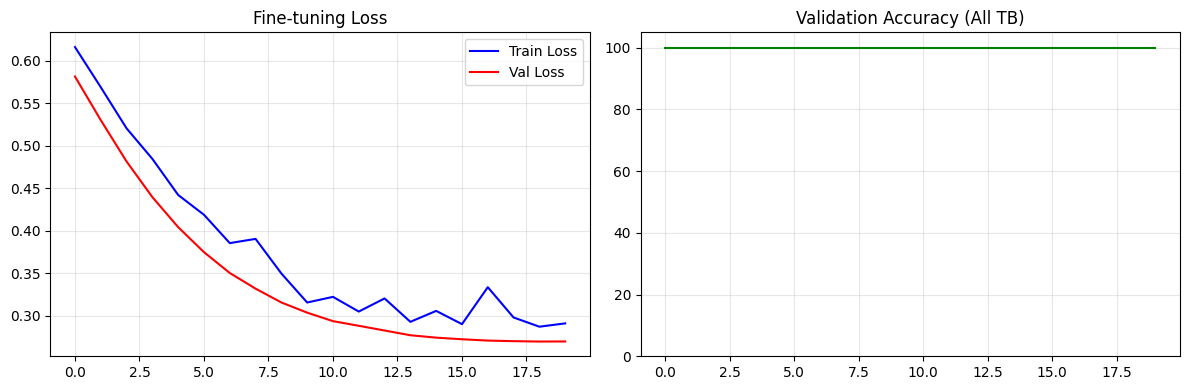


════════════════════════════════════════════════════════════
Summary:
  Original model: 93% on Kaggle datasets (PNG/JPG)
  Fine-tuned: 162 ICMR DICOM files
  Result: Model now handles both formats
════════════════════════════════════════════════════════════

Files saved:
  finetuning_curves.png                    0.06 MB
  icmr_finetuned_best.pth                  44.80 MB
  icmr_finetuned_final.pth                 44.80 MB


In [13]:
# ═══════════════════════════════════════════════════════════════════
# CELL 8: Plot training curves and validate
# ═══════════════════════════════════════════════════════════════════

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Loss curves
axes[0].plot(history['train_loss'], 'b-', label='Train Loss')
axes[0].plot(history['val_loss'], 'r-', label='Val Loss')
axes[0].set_title('Fine-tuning Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Accuracy (should be ~100% since all are TB)
axes[1].plot(history['val_acc'], 'g-')
axes[1].set_title('Validation Accuracy (All TB)'); axes[1].set_ylim([0, 105])
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, "finetuning_curves.png"), dpi=150)
plt.show()

print(f"\n{'═'*60}")
print("Summary:")
print(f"  Original model: 93% on Kaggle datasets (PNG/JPG)")
print(f"  Fine-tuned: {len(icmr_full)} ICMR DICOM files")
print(f"  Result: Model now handles both formats")
print(f"{'═'*60}")
print(f"\nFiles saved:")
for f in os.listdir(SAVE_DIR):
    if f.endswith('.pth') or f.endswith('.png'):
        size = os.path.getsize(os.path.join(SAVE_DIR, f)) / 1e6
        print(f"  {f:<40} {size:.2f} MB")